# WP06 · STRING protein ilişki ağları

**06.11.2026 · yalnız mevcut 9606 ve 511145 v12.0 dosyaları.** Protein ilişkisi, iki proteinin aynı biyolojik süreçte birlikte iş görmesi veya fiziksel bağlanması olabilir. Yerel `protein.links` dosyası genel işlevsel ilişki ağıdır; `protein.physical.links` değildir. Bu yüzden çizilen her kenar doğrudan fiziksel temas diye yorumlanmaz.

**Kimlik ayrımı:** 141 accession'dan 86'sı tek ve açık UniProt_AC alias'ına sahip; bunların 63'ünde taksonomi de aynı. Diğer 23, DrugBank K-12 (83333) → STRING MG1655 (511145) ebeveyn/alt suş kapsam farkıyla **ayrı keşif senaryosu**. Bunlar 23 kesin alt suş doğrulaması değildir ve strict analize sessizce eklenmez. Diğer türler ve eşleşmeyenler korunur. Notebook ham büyük kaynakları tekrar taramaz; model/PyG nesnesi oluşturmaz.

In [1]:
from pathlib import Path
import sys,json,pandas as pd,numpy as np
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'AGENTS.md').exists());sys.path.insert(0,str(ROOT/'scripts'))
from wp06_ppi import network_metrics,component_layout,THRESHOLDS
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import networkx as nx
import plotly.graph_objects as go
from IPython.display import display,FileLink
pd.set_option('display.max_rows',160);pd.set_option('display.max_colwidth',100)
QA=ROOT/'reports/qa/WP06';FIG=ROOT/'reports/figures/WP06';FIG.mkdir(parents=True,exist_ok=True)
def read(n):return pd.read_csv(QA/n,keep_default_na=False,dtype={'network_taxid':str})
mapping=read('protein_string_mapping.csv');nodes=read('ppi_nodes.csv');induced=read('ppi_induced_edges.csv');expanded=read('ppi_expanded_edges.csv');metrics=read('network_metrics.csv');summary=json.loads((QA/'coverage_summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{k:summary[k] for k in ['WP05_accessions','unique_accession_alias_match','strict_accession_and_exact_taxon','Ecoli_K12_exact_alias_parent_scope_review','unmatched_accession_alias','other_available_network_out_of_scope']}]))

,WP05_accessions,unique_accession_alias_match,strict_accession_and_exact_taxon,Ecoli_K12_exact_alias_parent_scope_review,unmatched_accession_alias,other_available_network_out_of_scope
0,141,86,63,23,6,49


## 1. Gerçek dosyalar, sütunlar ve kimlikler

STRING ID, organizma öneki ve o organizmadaki gen lokusu temsili içerir (`9606.ENSP...`, `511145.b...`). UniProt accession ile aynı dize değildir; regex ile önek ekleyerek dönüştürülemez. Aliases dosyası STRING ID/alias/source üçlüleri sağlar. Kimlik eşlemesi yalnız tam accession ve `UniProt_AC` kaynak etiketi üzerinden yapılır; gen adı benzerliği eşleme kanıtı değildir.

In [2]:
aliases=json.loads((QA/'aliases_manifest.json').read_text(encoding='utf-8'));links=json.loads((QA/'links_manifest.json').read_text(encoding='utf-8'));first=[x for x in links if x['statistics_scope']=='whole_file_rows']
files=pd.DataFrame([{'taxid':x['taxid'],'tip':x['kind'],'MiB':x['size_bytes']/2**20,'satır':x['rows'],'sütunlar':' / '.join(x['columns']),'skor_min':x.get('score_min','uygulanmaz'),'skor_max':x.get('score_max','uygulanmaz'),'boyut_mtime_korundu':x['metadata_unchanged']} for x in aliases+first]);display(files)
display(pd.DataFrame([{'taxid':x['taxid'],'tip':x['kind'],'örnek':str(x['examples'][0])} for x in aliases+first]))
display(read('alias_evidence.csv').head(12))

,taxid,tip,MiB,satır,sütunlar,skor_min,skor_max,boyut_mtime_korundu
0,9606,aliases,190.451263,3889207,string_protein_id / alias / source,uygulanmaz,uygulanmaz,True
1,511145,aliases,5.813360,154577,string_protein_id / alias / source,uygulanmaz,uygulanmaz,True
2,9606,links,601.681344,13715404,protein1 / protein2 / combined_score,150,999,True
3,511145,links,28.174241,984760,protein1 / protein2 / combined_score,150,999,True


,taxid,tip,örnek
0,9606,aliases,"['9606.ENSP00000000233', '2B6H', 'Ensembl_PDB']"
1,511145,aliases,"['511145.b0001', '944742', 'KEGG_GENEID']"
2,9606,links,"['9606.ENSP00000000233', '9606.ENSP00000356607', 173]"
3,511145,links,"['511145.b0001', '511145.b1715', 520]"


,accession,network_taxid,string_id,alias_source,source_line,source_path
0,Q9H015,9606,9606.ENSP00000200652,Ensembl_HGNC_uniprot_ids,36569,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.aliase...
1,Q9H015,9606,9606.ENSP00000200652,Ensembl_UniProt,36570,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.aliase...
2,Q9H015,9606,9606.ENSP00000200652,UniProt_AC,36571,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.aliase...
3,Q96BD0,9606,9606.ENSP00000217159,Ensembl_HGNC_uniprot_ids,70638,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.aliase...
4,Q96BD0,9606,9606.ENSP00000217159,Ensembl_UniProt,70639,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.aliase...
5,Q96BD0,9606,9606.ENSP00000217159,UniProt_AC,70640,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.aliase...
6,O43193,9606,9606.ENSP00000218721,Ensembl_HGNC_uniprot_ids,78589,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.aliase...
7,O43193,9606,9606.ENSP00000218721,Ensembl_UniProt,78590,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.aliase...
8,O43193,9606,9606.ENSP00000218721,UniProt_AC,78591,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.aliase...
9,P27169,9606,9606.ENSP00000222381,Ensembl_HGNC_uniprot_ids,105354,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.aliase...


**Yorum:** Links insan 13.715.404, E. coli 984.760 ham yönlü satır içeriyor. Bunlar tekil yönsüz kenar sayıları değildir. Skorlar 150–999; üç sütundan tek başına deneysel kanal, fiziksel temas veya aktarılmış kanıt ayrıştırılamaz. İlk akışta istatistik, induced kenarlar ve sınırlı komşu adayları çıkarıldı; ikinci links akışı, seçilen genişletilmiş düğümler arasındaki tam induced kenarları bulmak için gerekliydi. Hiçbir büyük dosyanın tüm satırları RAM'e alınmadı.

## 2. Taksonomi ve eşleme kararları

NCBI 83333 E. coli K-12, 511145 MG1655 alt suşudur; aynı çözünürlükte kimlik değildir. Mevcut alias kanıtı 23 K-12 accession'ını MG1655 ağına açıkça bağlıyor; bağımsız MG1655 dizi doğrulaması yapılmadı. Katı aynı-taxID analiz 63 insan proteiniyle sınırlı. E. coli şekilleri açıkça bu ayrı 23-alias senaryosudur. Kaynak E. coli genel tür ID 562 kayıtları alt suş varsayımıyla doldurulmaz.

,accession,protein_name,organism,taxid,organism_group,network_taxid,scope,status,string_id,candidate_count,alias_identity_unique,strict_taxon_match
0,A0A0H2XJ39,Penicillin-binding protein 3,Staphylococcus aureus (strain USA300),367830,bacteria,,outside_available_network_taxa,out_of_scope_organism,,0,False,False
1,B2ZTR6,Beta-lactamase,Acinetobacter baumannii,470,bacteria,,outside_available_network_taxa,out_of_scope_organism,,0,False,False
2,B4YQT9,Gyrase A,Mycobacterium tuberculosis,1773,bacteria,,outside_available_network_taxa,out_of_scope_organism,,0,False,False
3,C3T8E2,Multidrug resistance protein MdtK,Escherichia coli,562,bacteria,511145,species_only_strain_unresolved,unmatched_accession_alias,,0,False,False
4,D6R448,Penicillin-binding protein 2,Staphylococcus aureus,1280,bacteria,,outside_available_network_taxa,out_of_scope_organism,,0,False,False
5,O15244,Solute carrier family 22 member 2,Humans,9606,human,9606,exact_taxon,exact_alias_exact_taxon,9606.ENSP00000355920,1,True,True
6,O15245,Solute carrier family 22 member 1,Humans,9606,human,9606,exact_taxon,exact_alias_exact_taxon,9606.ENSP00000355930,1,True,True
7,O15439,ATP-binding cassette sub-family C member 4,Humans,9606,human,9606,exact_taxon,exact_alias_exact_taxon,9606.ENSP00000494609,1,True,True
8,O25608,Oxygen-insensitive NADPH nitroreductase,Helicobacter pylori (strain ATCC 700392 / 26695),85962,bacteria,,outside_available_network_taxa,out_of_scope_organism,,0,False,False
9,O43193,Motilin receptor,Humans,9606,human,9606,exact_taxon,exact_alias_exact_taxon,9606.ENSP00000218721,1,True,True


,accession,protein_name,organism,taxid,scope
3,C3T8E2,Multidrug resistance protein MdtK,Escherichia coli,562,species_only_strain_unresolved
14,P00484,Chloramphenicol acetyltransferase 3,Escherichia coli,562,species_only_strain_unresolved
15,P00551,Aminoglycoside 3'-phosphotransferase,Escherichia coli,562,species_only_strain_unresolved
74,P24093,Dr hemagglutinin structural subunit,Escherichia coli,562,species_only_strain_unresolved
97,P62593,Beta-lactamase TEM,Escherichia coli,562,species_only_strain_unresolved
111,Q47066,Beta-lactamase Toho-1,Escherichia coli,562,species_only_strain_unresolved


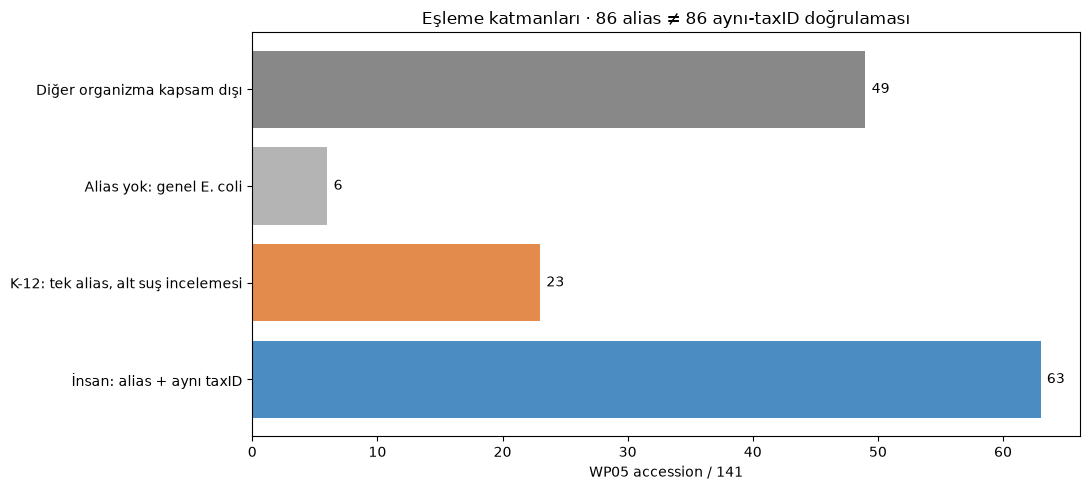

In [3]:
display(mapping)
display(mapping[mapping.status.eq('unmatched_accession_alias')][['accession','protein_name','organism','taxid','scope']])
labels=['İnsan: alias + aynı taxID','K-12: tek alias, alt suş incelemesi','Alias yok: genel E. coli','Diğer organizma kapsam dışı'];counts=[63,23,6,49]
fig,ax=plt.subplots(figsize=(11,5));ax.barh(labels,counts,color=['#4b8dc2','#e28b4d','#b4b4b4','#888888']);ax.set(xlabel='WP05 accession / 141',title='Eşleme katmanları · 86 alias ≠ 86 aynı-taxID doğrulaması')
for i,v in enumerate(counts):ax.text(v+.5,i,str(v),va='center')
plt.tight_layout();plt.savefig(FIG/'01_mapping_scope.png',dpi=160);plt.show()

**Yorum:** Belirsiz çok-STRING-ID eşlemesi gözlenmedi (0); bu hata yolu ayrıca test edilir. Aynı gen adını paylaşan farklı türler veya yalnız ad benzerliğiyle yapılan eşleme sayısı 0. 49 diğer organizma proteini için PPI yokluğu biyolojik izolasyon kanıtı değildir; yalnız mevcut iki ağın kapsamı dışında. 23 K-12 kaydı kabul edilirse alias-kimlik kapsamı 86 olur; katı taxID kapsamı yine 63 olarak ayrıca raporlanır.

## 3. Combined score: kenar desteği, risk değil

Combined score birden çok kanıt kanalının STRING yöntemine göre birleştirilmiş destek skorudur. Deneysel kesinlik, bağlanma gücü, yan etki olasılığı veya protein düğüm kalitesi değildir. Burada 150/400/700/900 önceden tanımlanmış keşif eşikleri; etiketler/model başarımı kullanılmadı. Ağırlıksız graf eşik üstü kenarın varlığını, ağırlıklı betimleme `w=score/1000` toplamını kullanır. Bu ağırlık protein.x'e eklenmez.

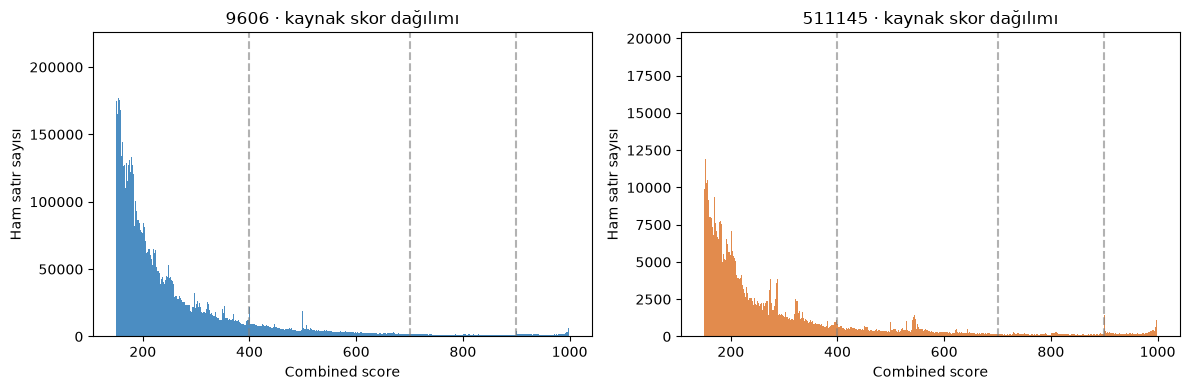

,yönsüz_çift,kaynak_satırı,iki_yönü_gözlenen,aynı_yön_tekrarı,skor_çatışması
network_taxid,,,,,
511145,130,260,130,0,0
9606,1200,2400,1200,0,0


,network_taxid,graph_type,threshold,mean_degree,mean_weighted_strength
0,9606,induced_seed,150,38.095238,16.718984
1,9606,induced_seed,400,18.507937,11.821397
2,9606,induced_seed,700,5.841270,4.991778
3,9606,induced_seed,900,2.507937,2.395587
4,9606,expanded_context,150,44.077670,18.740136
5,9606,expanded_context,400,18.737864,12.577398
6,9606,expanded_context,700,7.223301,6.424097
7,9606,expanded_context,900,4.058252,3.926602
8,511145,induced_seed,150,11.304348,7.369217
9,511145,induced_seed,400,7.304348,6.354261


In [4]:
hist=read('score_histogram.csv');fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,tax in zip(axes,['9606','511145']):
    h=hist[hist.network_taxid.eq(tax)];ax.bar(h.combined_score,h.raw_rows,width=1,color='#4b8dc2' if tax=='9606' else '#e28b4d')
    for threshold in [400,700,900]:ax.axvline(threshold,color='gray',ls='--',alpha=.6)
    ax.set(xlabel='Combined score',ylabel='Ham satır sayısı',title=f'{tax} · kaynak skor dağılımı')
plt.tight_layout();plt.savefig(FIG/'02_source_score_distribution.png',dpi=160);plt.show()
display(induced.groupby('network_taxid').agg(yönsüz_çift=('protein1','size'),kaynak_satırı=('source_rows','sum'),iki_yönü_gözlenen=('reciprocal_pair_observed','sum'),aynı_yön_tekrarı=('same_direction_duplicate_excess','sum'),skor_çatışması=('score_conflict','sum')))
display(metrics[['network_taxid','graph_type','threshold','mean_degree','mean_weighted_strength']])

**Yorum:** Kaynak skor histogramı ham satır ağırlıklıdır; global yönsüz tekilleştirme yapılmış gibi sunulmaz. Seçili induced ağlarda insan 2.400 satır→1.200 çift, E. coli keşif 260→130 çift; karşı yönler aynı skorlu. Self-loop, aynı-yön tekrarı veya skor çelişkisi bu seçili çiftlerde yok. Tüm kaynağın global aynı-yön duplicate sayısı ölçülmedi; bu sınır korunur. Ağırlıklı strength ile derece farklı niceliklerdir, ikisi de risk değil.

## 4. Induced ağlar, eşikler, derece ve bileşenler

Induced subgraph: seçili seed STRING düğümleri arasındaki kaynak kenarların tamamı. Kenar silinen düğümler graf veri yapısından atılmaz; izole düğümler sayılır. İki organizma arasında hiçbir PPI kenarı oluşturulmaz. Eşik artınca bağlantı zayıflaması, proteinin işlevsiz olduğu veya biyolojik etkileşimin yokluğu anlamına gelmez.

,network_taxid,graph_type,mapping_scope,threshold,nodes,edges,nonisolated_nodes,isolates,components,largest_component,density,mean_degree,mean_weighted_strength
0,9606,induced_seed,exact_taxon,150,63,1200,63,0,1,63,0.614439,38.095238,16.718984
1,9606,induced_seed,exact_taxon,400,63,583,61,2,3,61,0.298515,18.507937,11.821397
2,9606,induced_seed,exact_taxon,700,63,184,51,12,14,49,0.094214,5.841270,4.991778
3,9606,induced_seed,exact_taxon,900,63,79,36,27,32,26,0.040451,2.507937,2.395587
8,511145,induced_seed,K12_parent_scope_review,150,23,130,23,0,1,23,0.513834,11.304348,7.369217
9,511145,induced_seed,K12_parent_scope_review,400,23,84,23,0,1,23,0.332016,7.304348,6.354261
10,511145,induced_seed,K12_parent_scope_review,700,23,68,21,2,4,12,0.268775,5.913043,5.615217
11,511145,induced_seed,K12_parent_scope_review,900,23,56,21,2,5,10,0.221344,4.869565,4.763565


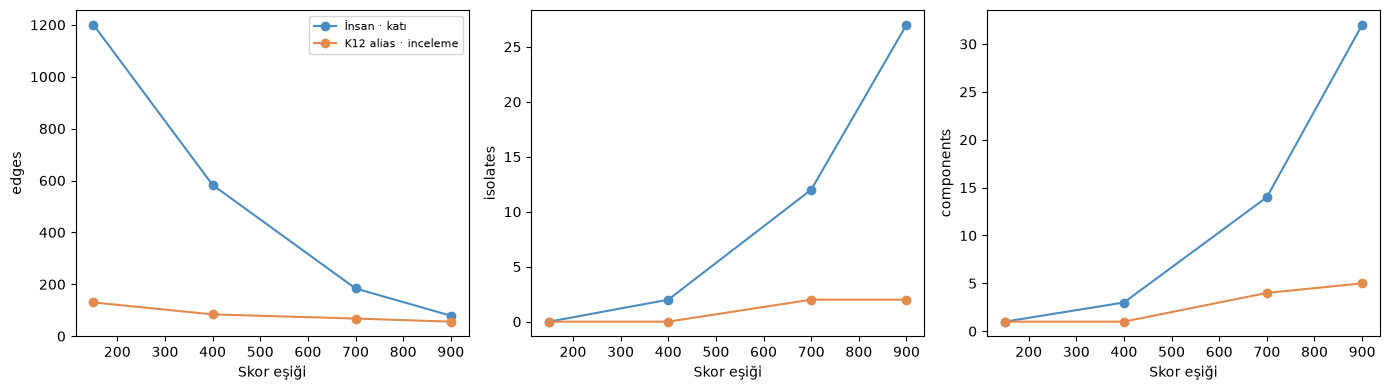

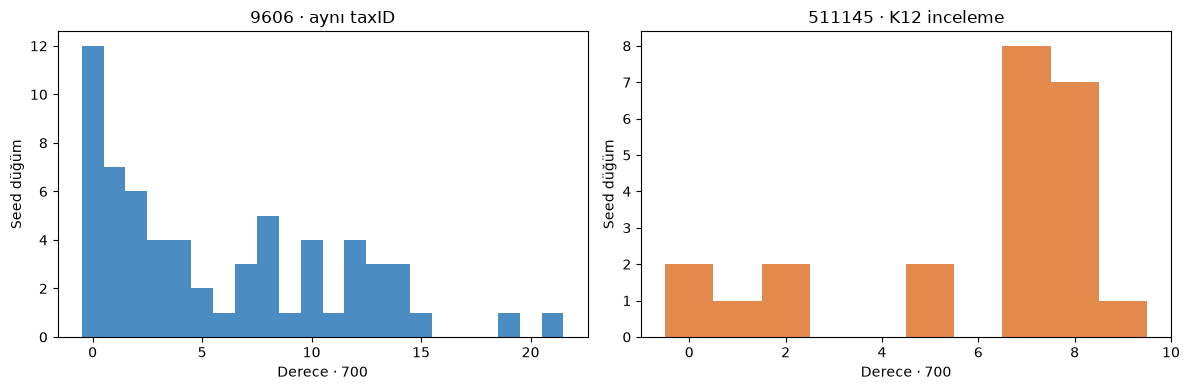

,network_taxid,component_index,nodes_700
0,9606,1,49
1,9606,2,2
2,9606,3,1
3,9606,4,1
4,9606,5,1
5,9606,6,1
6,9606,7,1
7,9606,8,1
8,9606,9,1
9,9606,10,1


In [5]:
seed_metrics=metrics[metrics.graph_type.eq('induced_seed')];display(seed_metrics)
fig,axes=plt.subplots(1,3,figsize=(14,4))
for tax,color,label in [('9606','#4b8dc2','İnsan · katı'),('511145','#e28b4d','K12 alias · inceleme')]:
    d=seed_metrics[seed_metrics.network_taxid.eq(tax)]
    for ax,col in zip(axes,['edges','isolates','components']):ax.plot(d.threshold,d[col],'-o',color=color,label=label);ax.set(xlabel='Skor eşiği',ylabel=col)
axes[0].legend(fontsize=8);plt.tight_layout();plt.savefig(FIG/'03_threshold_topology.png',dpi=160);plt.show()
def graph_for(tax,kind='induced_seed',threshold=700):
    ns=nodes[nodes.network_taxid.eq(tax)]
    if kind=='induced_seed':ns=ns[ns.node_role.eq('WP05_seed')];ed=induced[induced.network_taxid.eq(tax)]
    else:ed=expanded[expanded.network_taxid.eq(tax)]
    _,g=network_metrics(set(ns.string_id),ed.to_dict('records'),threshold)
    return g,ns
fig,axes=plt.subplots(1,2,figsize=(12,4));degree_rows=[];component_rows=[]
for ax,tax in zip(axes,['9606','511145']):
    g,ns=graph_for(tax);deg=dict(g.degree());ax.hist(list(deg.values()),bins=np.arange(max(deg.values())+2)-.5,color='#4b8dc2' if tax=='9606' else '#e28b4d');ax.set(xlabel='Derece · 700',ylabel='Seed düğüm',title=tax+(' · K12 inceleme' if tax=='511145' else ' · aynı taxID'))
    degree_rows.extend({'network_taxid':tax,'string_id':n,'degree_700':v,'weighted_strength_700':g.degree(n,weight='weight')} for n,v in deg.items())
    component_rows.extend({'network_taxid':tax,'component_index':i+1,'nodes_700':len(c)} for i,c in enumerate(sorted(nx.connected_components(g),key=lambda c:(-len(c),sorted(c)))))
pd.DataFrame(degree_rows).to_csv(QA/'degree_metrics_700.csv',index=False,encoding='utf-8-sig');pd.DataFrame(component_rows).to_csv(QA/'component_sizes_700.csv',index=False,encoding='utf-8-sig')
plt.tight_layout();plt.savefig(FIG/'04_degree_distributions.png',dpi=160);plt.show()
display(pd.DataFrame(component_rows))

**Yorum:** İnsan induced ağında 400 eşiğinde 583 kenar / 2 izole, 700'de 184 kenar / 12 izole, 900'de 79 kenar / 27 izole var. E. coli ayrı keşif senaryosunda aynı eşikler 84/68/56 kenar verir; 700'de 2 izole ve en büyük bileşen 12 düğüm. Sıklık/başarım etiketlerine bakılarak “en iyi eşik” seçilmedi; ağ yoğunluğu tek başına tahmin başarısı değildir.

## 5. İnsan ve E. coli kaynak PPI görselleri

Seed düğüm adları WP05 protein adlarıyla gösterim verisine bağlanır. STRING ID ve accession ayrı tutulur. Statik etiketler accession; etkileşimli HTML'de kimlik, ad, organizma, kapsam bayrağı ve her kenarın kaynak skoru görülebilir. Kenar kalınlığı görsel olarak skor/1000'le değişir; biyokimyasal kuvveti göstermez.

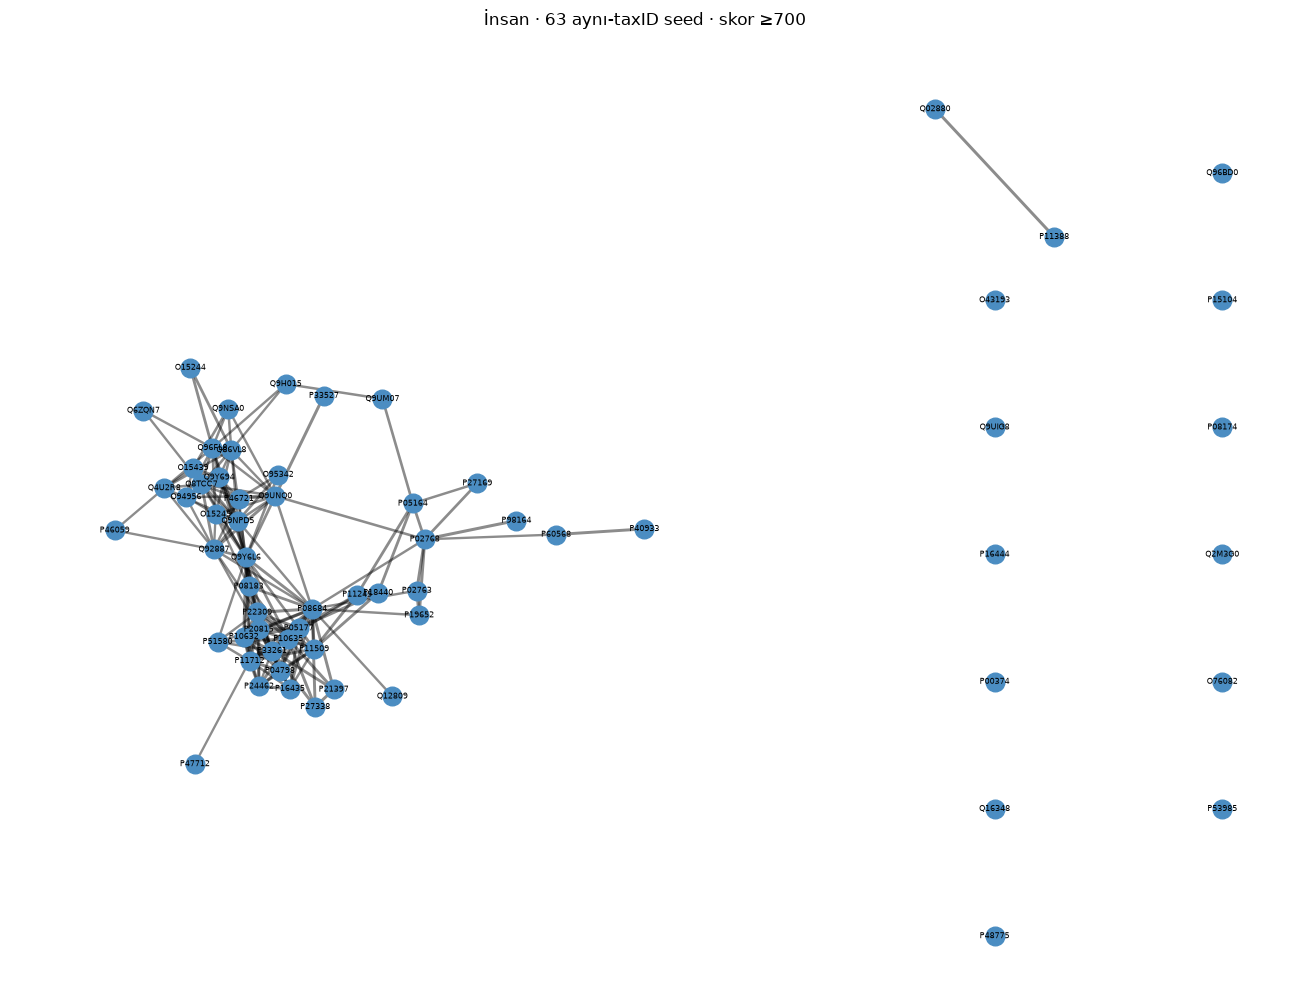

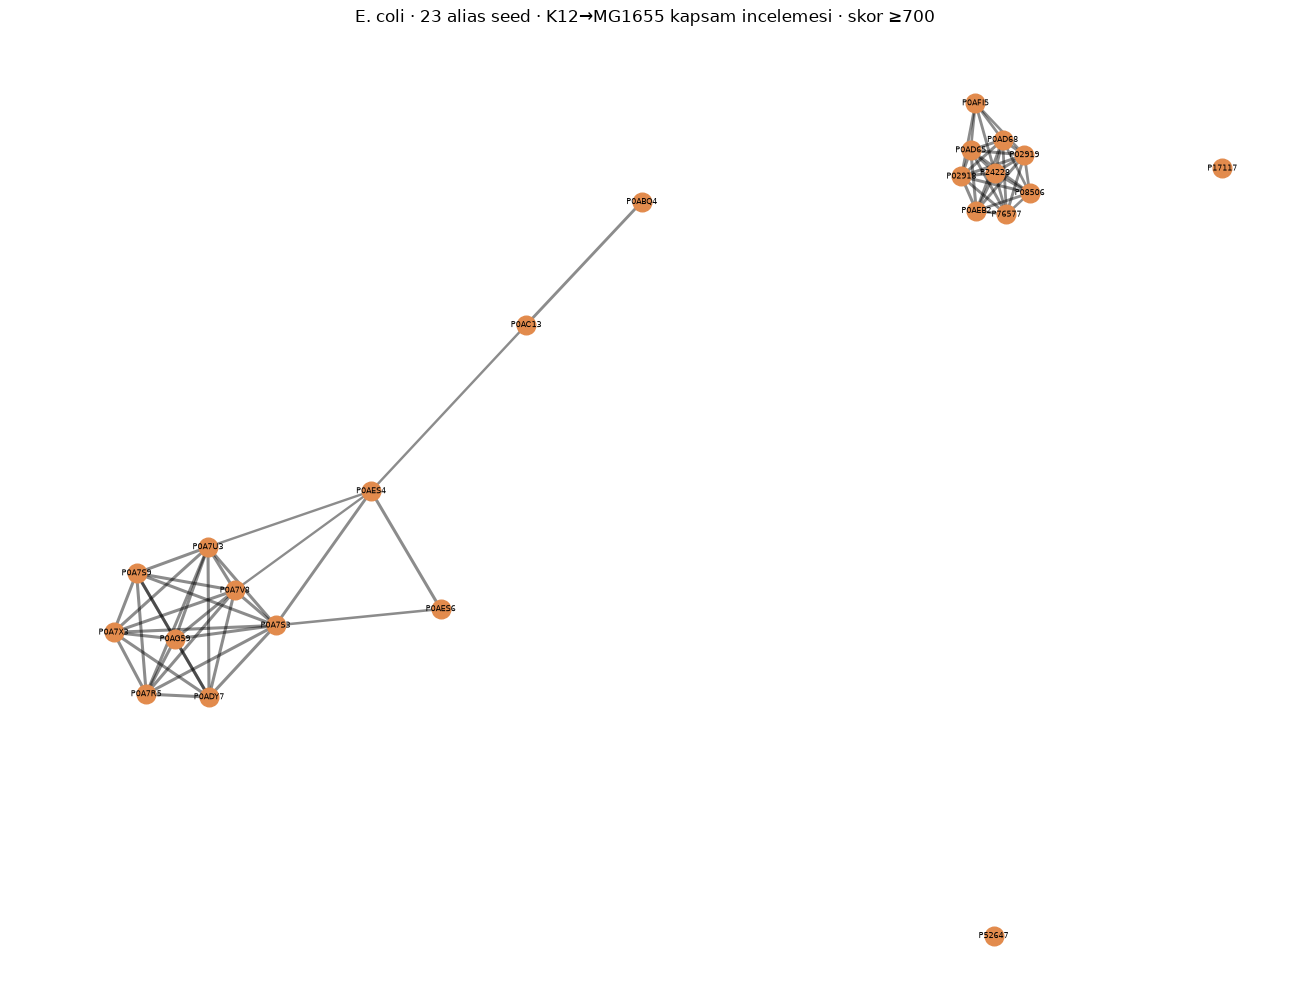

,network_taxid,string_id,degree_700,weighted_strength_700,protein_name,organism,accessions
0,9606,9606.ENSP00000498939,21,18.740,Cytochrome P450 3A4,Humans / 9606,P08684
1,9606,9606.ENSP00000256958,19,16.000,Solute carrier organic anion transporter family member 1B1,Humans / 9606,Q9Y6L6
2,9606,9606.ENSP00000260682,15,13.350,Cytochrome P450 2C9,Humans / 9606,P11712
3,9606,9606.ENSP00000304845,14,12.632,UDP-glucuronosyltransferase 1A1,Humans / 9606,P22309
4,9606,9606.ENSP00000360372,14,12.434,Cytochrome P450 2C19,Humans / 9606,P33261
5,9606,9606.ENSP00000222982,14,12.788,Cytochrome P450 3A5,Humans / 9606,P20815
6,9606,9606.ENSP00000498246,13,10.600,Broad substrate specificity ATP-binding cassette transporter ABCG2,Humans / 9606,Q9UNQ0
7,9606,9606.ENSP00000261196,13,10.423,Solute carrier organic anion transporter family member 1B3,Humans / 9606,Q9NPD5
8,9606,9606.ENSP00000342007,13,12.224,Cytochrome P450 1A2,Humans / 9606,P05177
9,9606,9606.ENSP00000270570,12,9.341,Multidrug and toxin extrusion protein 1,Humans / 9606,Q96FL8


In [6]:
def node_name(row):return row.protein_name or row.display_alias or row.string_id
def show_network(tax):
    g,ns=graph_for(tax);lookup=ns.set_index('string_id');pos=component_layout(g)
    fig,ax=plt.subplots(figsize=(13,10));color='#4b8dc2' if tax=='9606' else '#e28b4d'
    nx.draw_networkx_nodes(g,pos,ax=ax,node_color=color,node_size=180)
    nx.draw_networkx_edges(g,pos,ax=ax,width=[.4+1.8*g.edges[a,b]['weight'] for a,b in g.edges],alpha=.45)
    labels={n:lookup.loc[n,'accessions'] for n in g};nx.draw_networkx_labels(g,pos,labels=labels,font_size=6,ax=ax)
    ax.set_title(('İnsan · 63 aynı-taxID seed' if tax=='9606' else 'E. coli · 23 alias seed · K12→MG1655 kapsam incelemesi')+' · skor ≥700');ax.axis('off');plt.tight_layout();plt.savefig(FIG/('05_human_ppi.png' if tax=='9606' else '06_ecoli_scope_review_ppi.png'),dpi=170);plt.show()
for tax in ['9606','511145']:show_network(tax)
display(read('degree_metrics_700.csv').sort_values('degree_700',ascending=False).head(15).merge(nodes[['string_id','protein_name','organism','accessions']],on='string_id'))

**Yorum:** Grafikler 700 eşiğinde tüm seed düğümleri, izoleler dahil korur. Bileşenler okunabilirlik için ayrı yerleştirildi; konum/uzaklık biyolojik ölçü değildir. E. coli çizimi kaynak PPI kanıtı içerir fakat 23 DrugBank kaydının MG1655 alt suş aidiyeti bağımsız doğrulanmış değildir; bu katı insan ağıyla birleştirilmez. Derecesi yüksek düğüm, bu seçilmiş ağda daha çok kaynak komşusu taşır; ilaç yan etki riski kanıtı değildir.

## 6. Ayrı ve sınırlı genişletilmiş bağlam ağı

Etiket kullanılmadan önceden belirlenmiş seçim: her seed için skoru ≥700 olan en iyi üç farklı komşu; eşitlikte STRING ID sırası; organizma başına en fazla 40 yeni düğüm. Bu düğümler eklendikten sonra links dosyası ikinci akışta okunarak seçili tüm düğümler arası induced ilişkiler çıkarıldı. Bu, bütün bir-hop komşuluğu değildir; bütçeli ve seçime bağlı keşif ağıdır.

,string_id,network_taxid,selection_score,evidence_seed_STRING_ids,policy,drugbank_target
0,9606.ENSP00000216223,9606,999,9606.ENSP00000226730|9606.ENSP00000296545,"top3 per seed at >=700, score descending then ID, at most40 per organism",False
1,9606.ENSP00000216336,9606,999,9606.ENSP00000225275,"top3 per seed at >=700, score descending then ID, at most40 per organism",False
2,9606.ENSP00000231449,9606,999,9606.ENSP00000226730,"top3 per seed at >=700, score descending then ID, at most40 per organism",False
3,9606.ENSP00000231454,9606,999,9606.ENSP00000226730,"top3 per seed at >=700, score descending then ID, at most40 per organism",False
4,9606.ENSP00000233997,9606,999,9606.ENSP00000225275,"top3 per seed at >=700, score descending then ID, at most40 per organism",False
5,9606.ENSP00000234347,9606,999,9606.ENSP00000225275,"top3 per seed at >=700, score descending then ID, at most40 per organism",False
6,9606.ENSP00000242786,9606,999,9606.ENSP00000356030,"top3 per seed at >=700, score descending then ID, at most40 per organism",False
7,9606.ENSP00000245907,9606,999,9606.ENSP00000356030,"top3 per seed at >=700, score descending then ID, at most40 per organism",False
8,9606.ENSP00000252486,9606,999,9606.ENSP00000222381|9606.ENSP00000496870,"top3 per seed at >=700, score descending then ID, at most40 per organism",False
9,9606.ENSP00000273784,9606,999,9606.ENSP00000295897,"top3 per seed at >=700, score descending then ID, at most40 per organism",False


,string_id,display_alias,display_name_source,organism,node_role,sequence_feature_available
1,9606.ENSP00000216223,Interleukin-2 receptor subunit beta,UniProt_DE_RecName_Full,Humans / 9606,STRING_context_only,False
2,9606.ENSP00000216336,Cathepsin G,UniProt_DE_RecName_Full,Humans / 9606,STRING_context_only,False
9,9606.ENSP00000231449,Interleukin-4,UniProt_DE_RecName_Full,Humans / 9606,STRING_context_only,False
10,9606.ENSP00000231454,Interleukin-5,UniProt_DE_RecName_Full,Humans / 9606,STRING_context_only,False
11,9606.ENSP00000233997,Azurocidin,UniProt_DE_RecName_Full,Humans / 9606,STRING_context_only,False
12,9606.ENSP00000234347,Myeloblastin,UniProt_DE_RecName_Full,Humans / 9606,STRING_context_only,False
13,9606.ENSP00000236850,Apolipoprotein A-I,UniProt_DE_RecName_Full,Humans / 9606,STRING_context_only,False
14,9606.ENSP00000242786,CD97 antigen,UniProt_DE_RecName_Full,Humans / 9606,STRING_context_only,False
15,9606.ENSP00000245907,Acylation stimulating protein,UniProt_DE_RecName_Full,Humans / 9606,STRING_context_only,False
16,9606.ENSP00000252486,Apolipoprotein E,UniProt_DE_RecName_Full,Humans / 9606,STRING_context_only,False


,network_taxid,graph_type,mapping_scope,threshold,nodes,edges,nonisolated_nodes,isolates,components,largest_component,density,mean_degree,mean_weighted_strength
4,9606,expanded_context,exact_taxon,150,103,2270,103,0,1,103,0.432134,44.077670,18.740136
5,9606,expanded_context,exact_taxon,400,103,965,103,0,1,103,0.183705,18.737864,12.577398
6,9606,expanded_context,exact_taxon,700,103,372,96,7,10,85,0.070817,7.223301,6.424097
7,9606,expanded_context,exact_taxon,900,103,209,83,20,27,58,0.039787,4.058252,3.926602
12,511145,expanded_context,K12_parent_scope_review,150,63,755,63,0,1,63,0.386585,23.968254,14.068413
13,511145,expanded_context,K12_parent_scope_review,400,63,458,63,0,1,63,0.234511,14.539683,11.697524
14,511145,expanded_context,K12_parent_scope_review,700,63,307,63,0,2,59,0.157194,9.746032,9.080095
15,511145,expanded_context,K12_parent_scope_review,900,63,220,60,3,8,24,0.112647,6.984127,6.877270


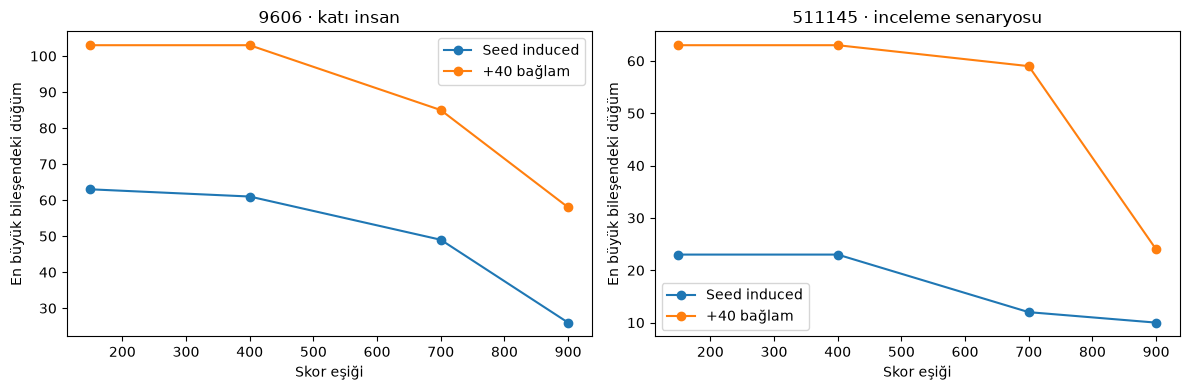

In [7]:
display(read('context_selection.csv').head(12));display(nodes[nodes.node_role.eq('STRING_context_only')][['string_id','display_alias','display_name_source','organism','node_role','sequence_feature_available']].head(14))
display(metrics[metrics.graph_type.eq('expanded_context')])
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,tax in zip(axes,['9606','511145']):
    for kind,label in [('induced_seed','Seed induced'),('expanded_context','+40 bağlam')]:
        d=metrics[metrics.network_taxid.eq(tax)&metrics.graph_type.eq(kind)];ax.plot(d.threshold,d.largest_component,'-o',label=label)
    ax.set(xlabel='Skor eşiği',ylabel='En büyük bileşendeki düğüm',title=tax+(' · inceleme senaryosu' if tax=='511145' else ' · katı insan'));ax.legend()
plt.tight_layout();plt.savefig(FIG/'07_context_comparison.png',dpi=160);plt.show()

**Yorum:** Eklenen 40'ar düğüm DrugBank ilaç hedefi veya dizisi doğrulanmış protein sayısına katılmaz. İsimler aliases içindeki açık ad kayıtlarından gelir; bu yalnız gösterim adı, ilaç hedef eşlemesi değildir. Bağlantılılık artışı seçimin doğal sonucu olabilir; GiG faydası kanıtı değildir. İnsan 700 eşiğinde geniş ağın 103 düğümünden 7'si izole; bu yüzden genişletme her seed'i bağlamadı. E. coli bağlamı da alt suş incelemesi bayrağını korur.

## 7. Etkileşimli ağ: seed / genişletilmiş görünüm

İki ayrı HTML aşağıda. Menü aynı organizmada seed-induced ve bütçeli bağlam görünümü arasında geçer. Düğüm hover'ı ID/ad/organizmayı, kenar orta noktasına hover combined score'u verir. İnternet istemeyen Plotly kodu HTML'e gömülüdür; protein dizisi veya öğrenme girdisi içermez.

In [8]:
def interactive(tax):
    traces=[];visibility=[]
    for kind in ['induced_seed','expanded_context']:
        g,ns=graph_for(tax,kind);lookup=ns.set_index('string_id');pos=component_layout(g)
        ex=[];ey=[];mx=[];my=[];eh=[]
        for a,b in g.edges:
            ex.extend([pos[a][0],pos[b][0],None]);ey.extend([pos[a][1],pos[b][1],None]);mx.append((pos[a][0]+pos[b][0])/2);my.append((pos[a][1]+pos[b][1])/2)
            eh.append(f'{a} ↔ {b}<br>combined_score={g.edges[a,b]["weight"]*1000:.0f}<br>Kaynak: {tax}.protein.links.v12.0.txt')
        visible=kind=='induced_seed'
        traces.append(go.Scatter(x=ex,y=ey,mode='lines',line=dict(color='#bdbdbd',width=1),hoverinfo='skip',visible=visible,showlegend=False))
        traces.append(go.Scatter(x=mx,y=my,mode='markers',marker=dict(size=6,color='rgba(80,80,80,.20)'),hovertext=eh,hoverinfo='text',visible=visible,showlegend=False))
        hover=[f'{n}<br>accession: {lookup.loc[n,"accessions"] or "DrugBank eşlemesi yok"}<br>ad: {node_name(lookup.loc[n])}<br>{lookup.loc[n,"organism"]}<br>{lookup.loc[n,"node_role"]}<br>{lookup.loc[n,"mapping_scope"]}' for n in g]
        traces.append(go.Scatter(x=[pos[n][0] for n in g],y=[pos[n][1] for n in g],mode='markers',marker=dict(size=11,color=['#4b8dc2' if lookup.loc[n,'node_role']=='WP05_seed' else '#a7a7a7' for n in g]),hovertext=hover,hoverinfo='text',visible=visible,showlegend=False))
    fig=go.Figure(traces);fig.update_layout(title=tax+' · skor ≥700'+(' · K12/MG1655 kapsam incelemesi' if tax=='511145' else ' · aynı taksonomi'),height=800,xaxis=dict(visible=False),yaxis=dict(visible=False),updatemenus=[dict(buttons=[dict(label='Seed induced',method='update',args=[{'visible':[True]*3+[False]*3}]),dict(label='+40 STRING bağlam',method='update',args=[{'visible':[False]*3+[True]*3}])])])
    path=FIG/f'{tax}_ppi_interactive.html';fig.write_html(path,include_plotlyjs=True,full_html=True);display(FileLink(str(path)))
for tax in ['9606','511145']:interactive(tax)

C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\figures\WP06\9606_ppi_interactive.html

C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\figures\WP06\511145_ppi_interactive.html

**Yorum:** HTML dosyalarının üretimi/içeriği kontrol edilir; canlı tarayıcı etkileşim testi yapılmadı. Ek düğümlerde ad/alias görünmesi onları DrugBank hedefi yapmaz. Bu görünümler gösterim amaçlıdır; katı taxID ağına E. coli seed'leri otomatik katılmaz.

## 8. İlaç–protein–protein: iki kenar tipi

İlaç–protein rolü DrugBank'tan; protein–protein ilişkisi STRING'den gelir. PPI doğrudan bir ilacın yeni hedefi olduğu anlamına gelmez. Küçük insan örneğinde en fazla dört ilaç ve sekiz doğrulanmış protein seçilir; DrugBank rollerinin tam izi ayrı CSV'dedir. Molekül ve protein katmanları karışmaz.

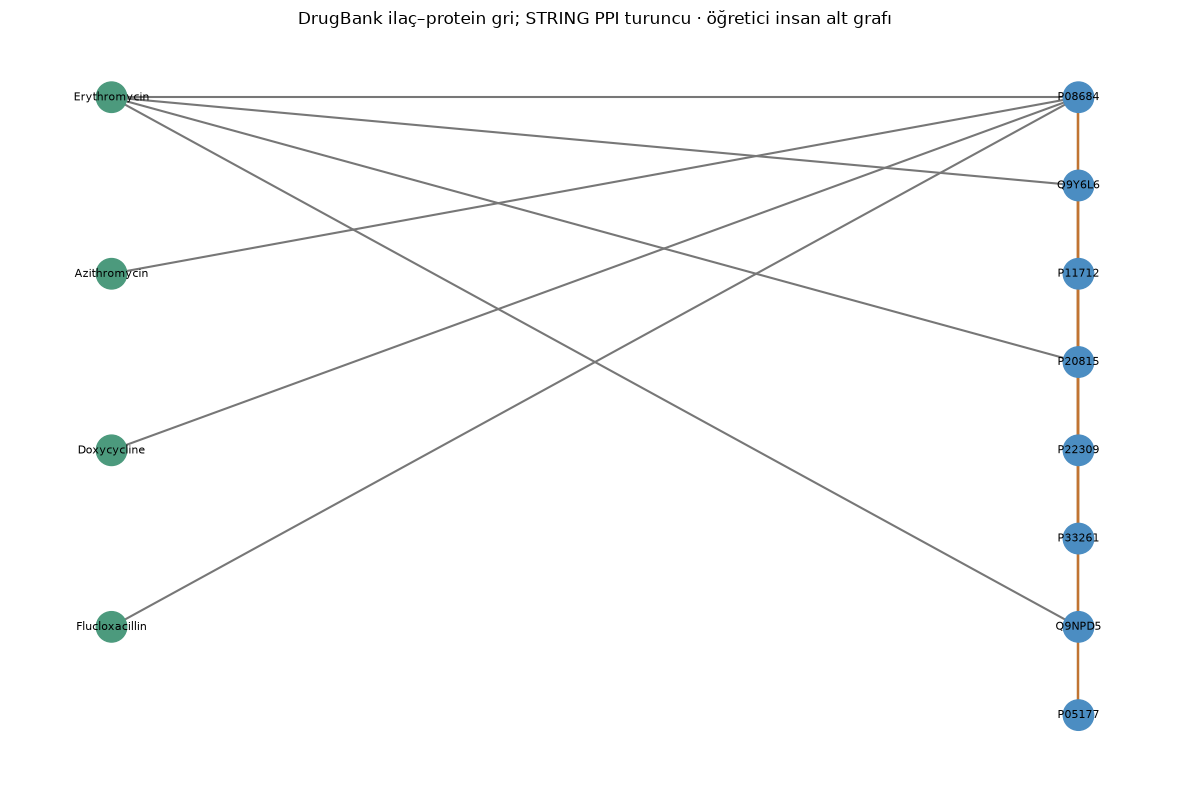

,drug_id,drug_name,WP05_proteins,strict_human_mapped_proteins,K12_alias_scope_review_proteins,retained_in_62
0,DB00199,Erythromycin,11,11,0,True
1,DB00207,Azithromycin,4,4,0,True
2,DB00254,Doxycycline,4,4,0,True
3,DB00259,Sulfanilamide,1,0,1,True
4,DB00301,Flucloxacillin,3,2,0,True
5,DB00303,Ertapenem,10,2,6,True
6,DB00319,Piperacillin,6,2,0,True
7,DB00359,Sulfadiazine,5,3,1,True
8,DB00415,Ampicillin,10,5,0,True
9,DB00417,Phenoxymethylpenicillin,4,1,1,True


In [9]:
dp=pd.read_csv(ROOT/'reports/qa/WP05/drug_protein_edges.csv');cohort=pd.read_csv(ROOT/'reports/qa/WP05/drug_coverage.csv');map_h=mapping[mapping.strict_taxon_match];g,ns=graph_for('9606')
high=sorted(g.nodes,key=lambda n:(-g.degree(n),n))[:8];acc_to_sid=map_h.set_index('accession').string_id.to_dict();subdp=dp[dp.accession.isin(map_h[map_h.string_id.isin(high)].accession)];drugs=sorted(subdp.drug_id.unique())[:4];subdp=subdp[subdp.drug_id.isin(drugs)]
T=nx.Graph();T.add_nodes_from('D:'+d for d in drugs);T.add_nodes_from(high)
for row in subdp.itertuples():T.add_edge('D:'+row.drug_id,acc_to_sid[row.accession],kind='drug_role')
for a,b in g.edges:
    if a in high and b in high:T.add_edge(a,b,kind='ppi')
pos={'D:'+d:(0,-i) for i,d in enumerate(drugs)}|{p:(1.4,-i*.5) for i,p in enumerate(high)};names=cohort.set_index('id').name.to_dict();lookup=ns.set_index('string_id');labels={n:names[n[2:]] if n.startswith('D:') else lookup.loc[n,'accessions'] for n in T}
fig,ax=plt.subplots(figsize=(12,8));nx.draw_networkx_nodes(T,pos,ax=ax,node_color=['#4c9a7d' if n.startswith('D:') else '#4b8dc2' for n in T],node_size=480);nx.draw_networkx_labels(T,pos,labels=labels,font_size=8,ax=ax)
for kind,color in [('drug_role','#777777'),('ppi','#c17432')]:nx.draw_networkx_edges(T,pos,ax=ax,edgelist=[(a,b) for a,b,d in T.edges(data=True) if d['kind']==kind],edge_color=color,width=1.5)
ax.set_title('DrugBank ilaç–protein gri; STRING PPI turuncu · öğretici insan alt grafı');ax.axis('off');plt.tight_layout();plt.savefig(FIG/'08_drug_protein_ppi_example.png',dpi=170);plt.show()
display(read('drug_ppi_mapping_coverage.csv'))

**Yorum:** Kenarların kaynakları ve anlamları farklıdır. Paylaşılan bir CYP/taşıyıcı düğümünden gelen ağ bağlantısı antibakteriyel mekanizmanın kanıtı değildir. Tobramycin ve Methenamine, protein/PPI modalitesi eksik olarak 62 ilaçlık kohortta kalır. WP04'ün sekiz moleküler QC kararı değişmedi.

## 9. Eski V6 forward denetimi ve gelecekteki GiG tasarımı

Eski kod PPI edge_index'i HeteroData'ya yazıyor; `forward` yalnız x_drug/x_prot/x_se/dp_ei ve tahmin indekslerini alıyor. Protein temsili MLP; PPI komşularından güncellenmiyor. Ardından drug→protein mean aggregation yapılıyor. Dolayısıyla eski modelde PPI hazırlanmış, fakat protein ağında öğrenilen mesaj geçişi yok. Sınıf adının GiG olması bunu değiştirmez. AST denetimi eski kodu çalıştırmadan yapılmıştır.

,forward_satırı,parametreler,PPI_parametresi,protein_encoder
0,733,"self, x_drug, x_prot, x_se, dp_ei, pred_drug_idx, pred_se_idx",False,h_prot = self.prot_enc(x_prot)


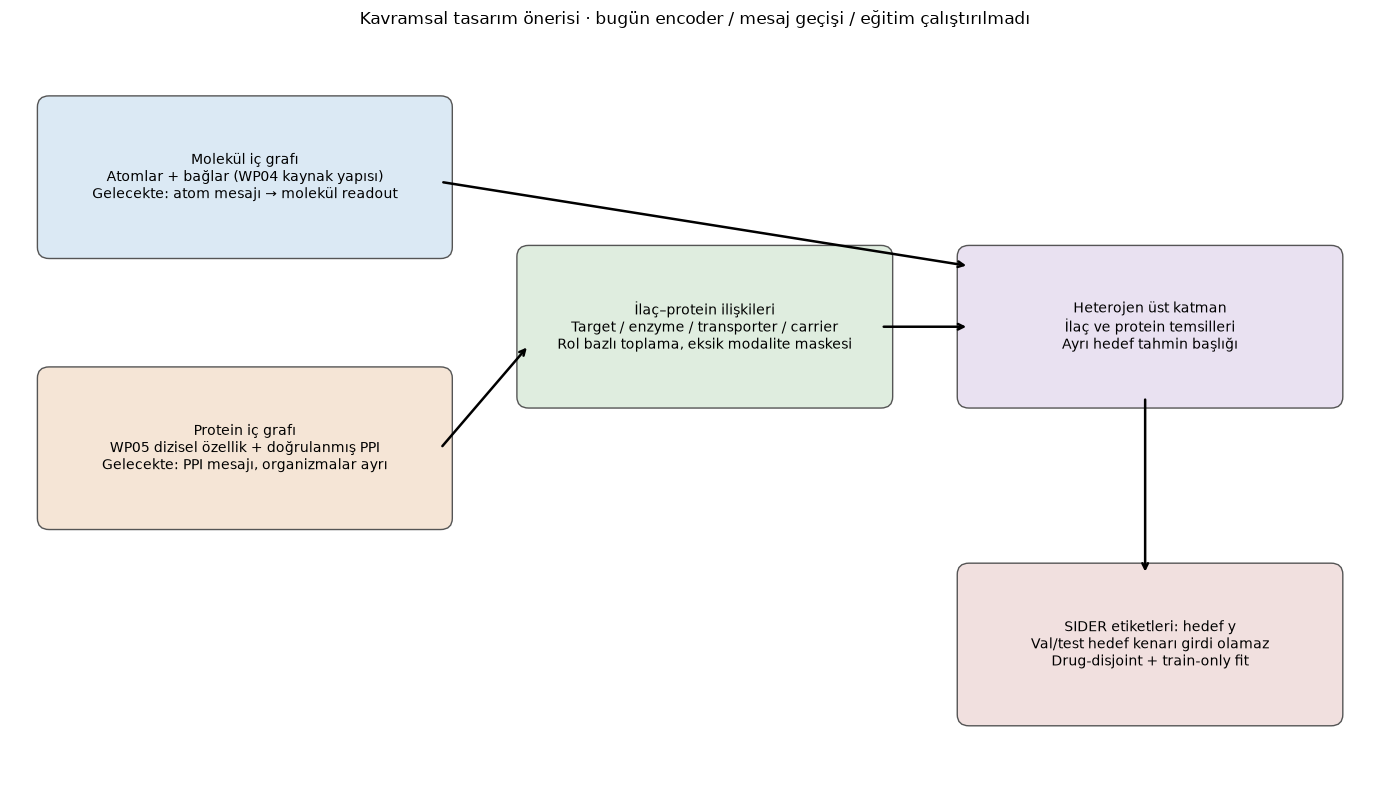

In [10]:
audit=json.loads((QA/'legacy_forward_audit.json').read_text(encoding='utf-8'));display(pd.DataFrame([{'forward_satırı':audit['forward_line'],'parametreler':', '.join(audit['forward_args']),'PPI_parametresi':audit['ppi_argument_present'],'protein_encoder':audit['protein_encoder_expression']}]))
fig,ax=plt.subplots(figsize=(14,8));ax.set(xlim=(0,14),ylim=(0,8));ax.axis('off')
def box(x,y,w,h,text,color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.12',facecolor=color,edgecolor='#555555'));ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=10,wrap=True)
box(.4,5.7,4,1.5,'Molekül iç grafı\nAtomlar + bağlar (WP04 kaynak yapısı)\nGelecekte: atom mesajı → molekül readout','#dbe9f4')
box(.4,2.8,4,1.5,'Protein iç grafı\nWP05 dizisel özellik + doğrulanmış PPI\nGelecekte: PPI mesajı, organizmalar ayrı','#f5e5d6')
box(5.3,4.1,3.6,1.5,'İlaç–protein ilişkileri\nTarget / enzyme / transporter / carrier\nRol bazlı toplama, eksik modalite maskesi','#dfeddf')
box(9.8,4.1,3.7,1.5,'Heterojen üst katman\nİlaç ve protein temsilleri\nAyrı hedef tahmin başlığı','#e9e1f1')
box(9.8,.7,3.7,1.5,'SIDER etiketleri: hedef y\nVal/test hedef kenarı girdi olamaz\nDrug-disjoint + train-only fit','#f1e0df')
for a,b in [((4.4,6.4),(9.8,5.5)),((4.4,3.55),(5.3,4.65)),((8.9,4.85),(9.8,4.85)),((11.6,4.1),(11.6,2.2))]:ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',lw=1.8))
ax.set_title('Kavramsal tasarım önerisi · bugün encoder / mesaj geçişi / eğitim çalıştırılmadı');plt.tight_layout();plt.savefig(FIG/'09_gig_design_concept.png',dpi=170);plt.show()

**Yorum:** Dört yapı ayrı: atom/bağ grafı, PPI grafı, ilaç–protein bağları ve heterojen üst katman. Gelecekte PPI komşu güncellemesi gerçekten forward'da işlenmeli; PPI kenarları çıkarılınca/karıştırılınca çıktının değişmesi ve uygun ablation ile katkı sınanmalı. Bugün mimari kodlanmadı. Context düğümleri için dizi/özellik politikası henüz yok; STRING combined score protein özelliği yerine geçmez.

## Kapanış ve karar kapısı

Katı insan induced ağında bağlantı var; bu ileride kontrollü PPI deneyi için topolojik gerekçe sağlar, faydayı kanıtlamaz. 78/141 accession katı aynı-taxID kapsamı dışında (23'ü K12 alias incelemesinde). E. coli senaryosu için ebeveyn/alt suş kapsamı kabulü ayrıca karar gerektirir; diğer türler eşlenmez. Nihai eşik, genişleme veya model politikası burada seçilmedi. 62 ilaç, iki eksik protein modalitesi ve sekiz WP04 inceleme molekülü korunur.

Dokuz PNG ve iki HTML, mevcut QA tablolarından üretildi. Ağsız protein, negatif biyolojik etkileşim anlamına gelmez. PT/kategori/skor/etiket bulunurluğu PPI düğüm girdisi yapılmadı. Model, PyG nesnesi, split, negatif örnek veya eğitim yok. WP06 sonunda kullanıcı onayı beklenir.

Kaynaklar: [STRING skor anlamı](https://string-db.org/help/scores/), [v12 dosya tanımı](https://version-12-0.string-db.org/cgi/download), [MG1655 taksonomisi](https://www.ncbi.nlm.nih.gov/Taxonomy/Browser/wwwtax.cgi?id=511145&mode=Info).